# La pratica sportiva in Italia, 2014-2024
**Progetto Big Data for Official Statistics – analisi esplorativa**

Fonte: ISTAT, *Aspetti della vita quotidiana*, file ad uso pubblico 2014-2024, armonizzati con `scripts/costruisci_avq.py`.

Tutte le stime sono **pesate** con il coefficiente di riporto all'universo (`peso`). Gli intervalli di confidenza al 95% sono **approssimati**: il file pubblico non contiene strati e unità primarie, quindi usiamo l'ampiezza campionaria effettiva di Kish, $n_{eff} = (\sum w)^2 / \sum w^2$, che tiene conto dei pesi ma non dell'effetto grappolo. Gli intervalli veri sono un po' più larghi.

**Indice**
1. Andamento 2014-2024
2. Sport ed età: dove si smette
3. Giovani 11-24 anni: andamento per sesso
4. Divari territoriali
5. Titolo di studio
6. Sport e recupero scolastico (11-19 anni)
7. Perché i giovani non fanno sport (tavole ISTAT 2024)

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "figures"
RES = ROOT / "results"
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

dati = pd.read_parquet(ROOT / "data" / "processed" / "avq_sport_2014_2024.parquet")
dati = dati[dati["eta_classe"] != "0-2"]  # come ISTAT: persone di 3 anni e più
print(f"{len(dati):,} individui, anni {dati.anno.min()}-{dati.anno.max()}")

479,711 individui, anni 2014-2024


In [2]:
# Palette e stile (palette di riferimento della skill dataviz, modalità chiara)
SUPERFICIE, TESTO, TESTO_2, GRIGLIA = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLU, ARANCIO, ACQUA, GIALLO, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
COLORI_SESSO = {"Maschio": BLU, "Femmina": ARANCIO}

plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "text.color": TESTO, "axes.labelcolor": TESTO_2, "xtick.color": TESTO_2, "ytick.color": TESTO_2,
    "axes.edgecolor": GRIGLIA, "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRIGLIA, "grid.linewidth": 0.8, "lines.linewidth": 2,
    "legend.frameon": False, "axes.axisbelow": True,
})

def fonte(ax, testo="Fonte: elaborazione su microdati ISTAT AVQ (file ad uso pubblico)", y=-0.16):
    ax.annotate(testo, xy=(0, y), xycoords="axes fraction", fontsize=8, color=TESTO_2)

def etichette_finali(ax, x, valori, testi, distanza=1.4):
    """Etichette a destra dell'ultimo punto, spostate in verticale se troppo vicine."""
    ordine = np.argsort(valori)
    pos = np.array(valori, dtype=float)[ordine]
    for i in range(1, len(pos)):
        pos[i] = max(pos[i], pos[i - 1] + distanza)
    for j, i in enumerate(ordine):
        ax.annotate(testi[i], (x, valori[i]), xytext=(x + 0.25, pos[j]), textcoords="data",
                    va="center", fontsize=9, color=TESTO)

def salva(fig, nome):
    fig.savefig(FIG / f"{nome}.png")

In [3]:
def quota(df, col, by):
    """Quota pesata (%) di `col` == True per gruppo, con IC 95% approssimato (Kish)."""
    def calc(g):
        g = g[g[col].notna()]
        w, y = g["peso"].to_numpy(), g[col].astype(float).to_numpy()
        p = np.average(y, weights=w)
        n_eff = w.sum() ** 2 / (w ** 2).sum()
        se = np.sqrt(p * (1 - p) / n_eff)
        return pd.Series({"quota": 100 * p, "ic_basso": 100 * (p - 1.96 * se),
                          "ic_alto": 100 * (p + 1.96 * se), "n": len(g)})
    return df.groupby(by, observed=True).apply(calc, include_groups=False).reset_index()

## 1. Andamento 2014-2024
Quota di persone di 3 anni e più che praticano sport (in modo continuativo o saltuario).

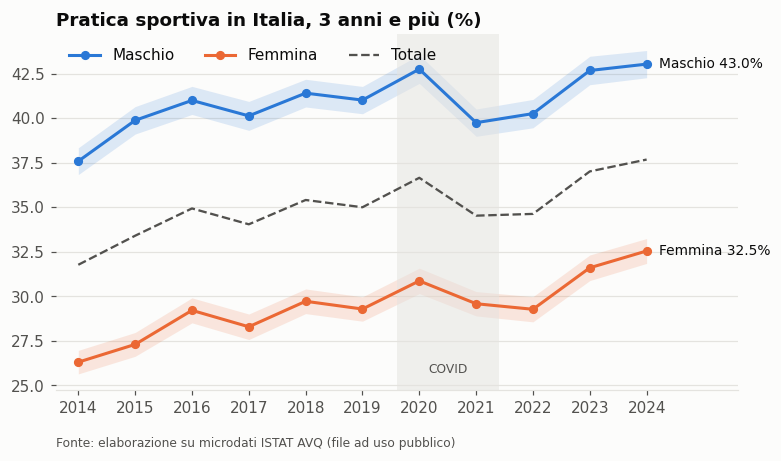

,anno,quota,ic_basso,ic_alto,n
0,2014,31.8,31.3,32.3,43755.0
1,2015,33.4,32.9,33.9,43989.0
2,2016,34.9,34.4,35.5,42235.0
3,2017,34.0,33.5,34.6,47603.0
4,2018,35.4,34.9,35.9,43462.0
5,2019,35.0,34.5,35.5,44537.0
6,2020,36.6,36.1,37.2,41966.0
7,2021,34.5,34.0,35.0,44879.0
8,2022,34.6,34.1,35.2,41305.0
9,2023,37.0,36.5,37.5,40931.0


In [4]:
trend = quota(dati, "pratica_sport", ["anno"])
trend_sesso = quota(dati, "pratica_sport", ["anno", "sesso"])
trend_sesso.to_csv(RES / "trend_pratica_sesso.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.2))
for sesso, g in trend_sesso.groupby("sesso", observed=True):
    c = COLORI_SESSO[sesso]
    ax.fill_between(g.anno, g.ic_basso, g.ic_alto, color=c, alpha=0.15, linewidth=0)
    ax.plot(g.anno, g.quota, color=c, marker="o", markersize=5, label=sesso)
    ultimo = g.iloc[-1]
    ax.annotate(f"{sesso} {ultimo.quota:.1f}%", (ultimo.anno, ultimo.quota), xytext=(8, 0),
                textcoords="offset points", va="center", color=TESTO, fontsize=9)
ax.plot(trend.anno, trend.quota, color=TESTO_2, linestyle="--", linewidth=1.5, label="Totale")
ax.axvspan(2019.6, 2021.4, color=GRIGLIA, alpha=0.5, linewidth=0)
ax.text(2020.5, ax.get_ylim()[0] + 1, "COVID", ha="center", fontsize=8, color=TESTO_2)
ax.set_title("Pratica sportiva in Italia, 3 anni e più (%)")
ax.set_xticks(range(2014, 2025))
ax.set_xlim(2013.6, 2025.6)
ax.legend(loc="upper left", ncols=3)
fonte(ax)
salva(fig, "01_trend_pratica_sesso")
plt.show()
trend.round(1)

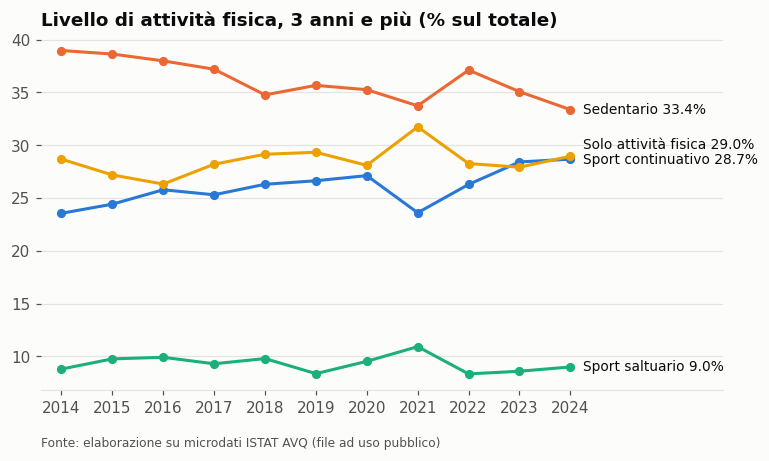

livello_attivita,Sport continuativo,Sport saltuario,Solo attività fisica,Sedentario
anno,,,,
2014,23.6,8.8,28.7,39.0
2015,24.4,9.8,27.2,38.6
2016,25.8,9.9,26.3,38.0
2017,25.3,9.3,28.2,37.2
2018,26.3,9.8,29.1,34.8
2019,26.6,8.4,29.3,35.7
2020,27.1,9.5,28.1,35.3
2021,23.6,10.9,31.7,33.7
2022,26.3,8.3,28.3,37.1


In [5]:
# Composizione: sport continuativo, saltuario, solo attività fisica, sedentari
comp = (dati[dati.livello_attivita.notna()]
        .groupby(["anno", "livello_attivita"], observed=True)["peso"].sum()
        .groupby(level=0).transform(lambda s: 100 * s / s.sum()).unstack())
comp.to_csv(RES / "composizione_attivita.csv")

fig, ax = plt.subplots(figsize=(8, 4.2))
colori = [BLU, ACQUA, GIALLO, ARANCIO]
for (livello, s), c in zip(comp.items(), colori):
    ax.plot(s.index, s.values, color=c, marker="o", markersize=5)
etichette_finali(ax, 2024, comp.iloc[-1].tolist(),
                 [f"{l} {v:.1f}%" for l, v in comp.iloc[-1].items()])
ax.set_title("Livello di attività fisica, 3 anni e più (% sul totale)")
ax.set_xticks(range(2014, 2025))
ax.set_xlim(2013.6, 2027)
fonte(ax)
salva(fig, "02_composizione_attivita")
plt.show()
comp.round(1)

## 2. Sport ed età: dove si smette
Media 2022-2024, per avere campioni più grandi in ogni classe di età. Il calo dopo i 15 anni è la "curva dell'abbandono": i microdati non dicono *perché* si smette, ma mostrano *quando* e *per chi*.

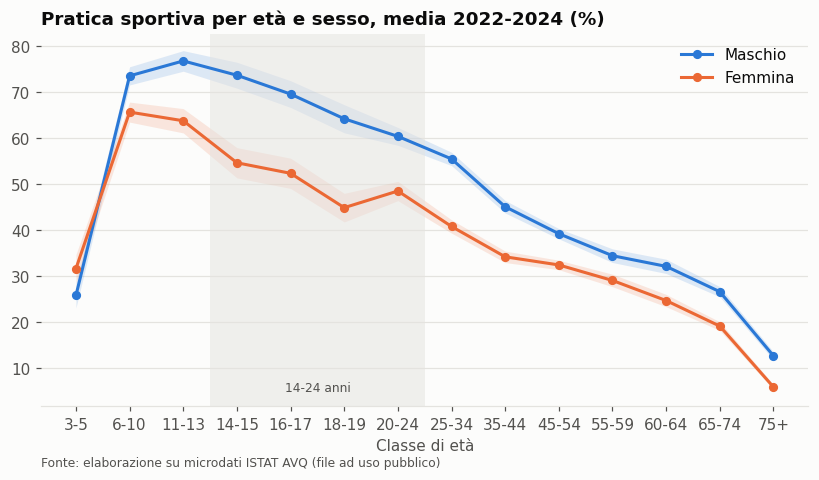

sesso,Maschio,Femmina
eta_classe,,
3-5,25.8,31.6
6-10,73.5,65.6
11-13,76.7,63.7
14-15,73.6,54.6
16-17,69.5,52.3
18-19,64.2,44.9
20-24,60.4,48.5
25-34,55.5,40.8
35-44,45.1,34.2


In [6]:
recenti = dati[dati.anno >= 2022]
eta = quota(recenti, "pratica_sport", ["eta_classe", "sesso"])
eta.to_csv(RES / "pratica_eta_sesso_2022_2024.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4.4))
x = np.arange(eta.eta_classe.nunique())
for sesso, g in eta.groupby("sesso", observed=True):
    c = COLORI_SESSO[sesso]
    ax.fill_between(x, g.ic_basso, g.ic_alto, color=c, alpha=0.15, linewidth=0)
    ax.plot(x, g.quota, color=c, marker="o", markersize=5, label=sesso)
ax.set_xticks(x, eta.eta_classe.cat.categories[1:], rotation=0)
ax.axvspan(2.5, 6.5, color=GRIGLIA, alpha=0.5, linewidth=0)
ax.text(4.5, 5, "14-24 anni", ha="center", fontsize=8, color=TESTO_2)
ax.set_title("Pratica sportiva per età e sesso, media 2022-2024 (%)")
ax.set_xlabel("Classe di età")
ax.legend(loc="upper right")
fonte(ax)
salva(fig, "03_pratica_eta_sesso")
plt.show()
eta.pivot(index="eta_classe", columns="sesso", values="quota").round(1)

## 3. Giovani 11-24 anni: andamento per sesso

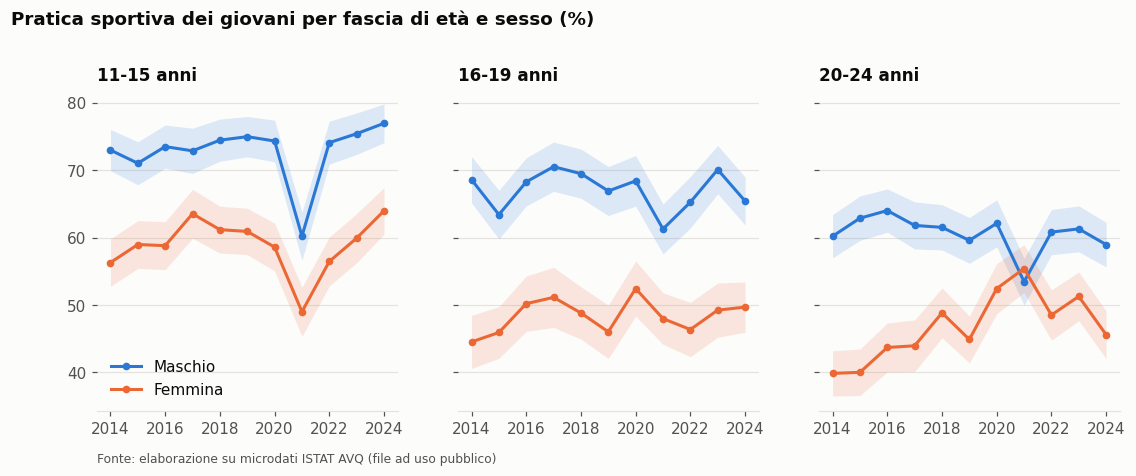

In [7]:
GIOVANI = ["11-13", "14-15", "16-17", "18-19", "20-24"]
giovani = dati[dati.eta_classe.isin(GIOVANI)].copy()
giovani["fascia"] = giovani.eta_classe.map(
    {"11-13": "11-15", "14-15": "11-15", "16-17": "16-19", "18-19": "16-19", "20-24": "20-24"})
g_trend = quota(giovani, "pratica_sport", ["fascia", "anno", "sesso"])
g_trend.to_csv(RES / "trend_giovani_fascia_sesso.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, (fascia, gf) in zip(axes, g_trend.groupby("fascia")):
    for sesso, g in gf.groupby("sesso", observed=True):
        c = COLORI_SESSO[sesso]
        ax.fill_between(g.anno, g.ic_basso, g.ic_alto, color=c, alpha=0.15, linewidth=0)
        ax.plot(g.anno, g.quota, color=c, marker="o", markersize=4, label=sesso)
    ax.set_title(f"{fascia} anni", fontsize=11)
    ax.set_xticks([2014, 2016, 2018, 2020, 2022, 2024])
axes[0].legend(loc="lower left")
fig.suptitle("Pratica sportiva dei giovani per fascia di età e sesso (%)", x=0.06, ha="left",
             fontweight="bold", y=1.02)
fig.subplots_adjust(top=0.84)
fonte(axes[0])
salva(fig, "04_trend_giovani")
plt.show()

In [8]:
# Divario di genere (punti percentuali, maschi - femmine)
divario = (g_trend.pivot_table(index="anno", columns=["fascia", "sesso"], values="quota", observed=True))
divario = pd.DataFrame({f: divario[(f, "Maschio")] - divario[(f, "Femmina")]
                        for f in ["11-15", "16-19", "20-24"]})
divario.round(1)

,11-15,16-19,20-24
anno,,,
2014,16.7,24.1,20.3
2015,12.1,17.5,22.9
2016,14.7,18.1,20.3
2017,9.3,19.4,17.9
2018,13.3,20.7,12.7
2019,14.1,20.9,14.7
2020,15.7,16.0,9.7
2021,11.2,13.3,-2.0
2022,17.6,18.9,12.3


## 4. Divari territoriali
Le regioni hanno campioni piccoli, quindi uniamo gli anni 2022-2024. Il confronto con il periodo 2014-2016 mostra chi è migliorato.

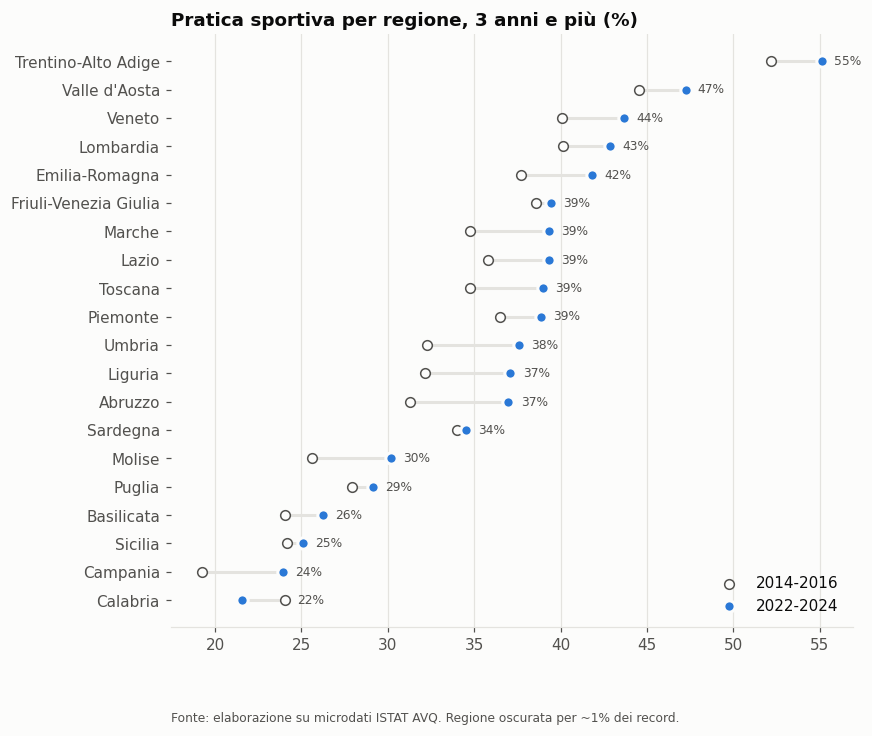

In [9]:
reg_recenti = quota(dati[dati.anno >= 2022], "pratica_sport", ["regione"])
reg_inizio = quota(dati[dati.anno <= 2016], "pratica_sport", ["regione"])
reg = reg_recenti.merge(reg_inizio[["regione", "quota"]], on="regione", suffixes=("", "_2014_2016"))
reg = reg.sort_values("quota")
reg.to_csv(RES / "pratica_regioni.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 7))
y = np.arange(len(reg))
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.hlines(y, reg.quota_2014_2016, reg.quota, color=GRIGLIA, linewidth=2)
ax.scatter(reg.quota_2014_2016, y, color=SUPERFICIE, edgecolor=TESTO_2, s=40, zorder=3,
           label="2014-2016")
ax.scatter(reg.quota, y, color=BLU, s=55, zorder=4, edgecolor=SUPERFICIE, linewidth=2,
           label="2022-2024")
for yi, q, q0 in zip(y, reg.quota, reg.quota_2014_2016):
    ax.annotate(f"{q:.0f}%", (max(q, q0), yi), xytext=(8, 0), textcoords="offset points", va="center",
                fontsize=8, color=TESTO_2)
ax.set_yticks(y, reg.regione)
ax.set_title("Pratica sportiva per regione, 3 anni e più (%)")
ax.legend(loc="lower right")
fonte(ax, "Fonte: elaborazione su microdati ISTAT AVQ. Regione oscurata per ~1% dei record.")
salva(fig, "05_regioni")
plt.show()

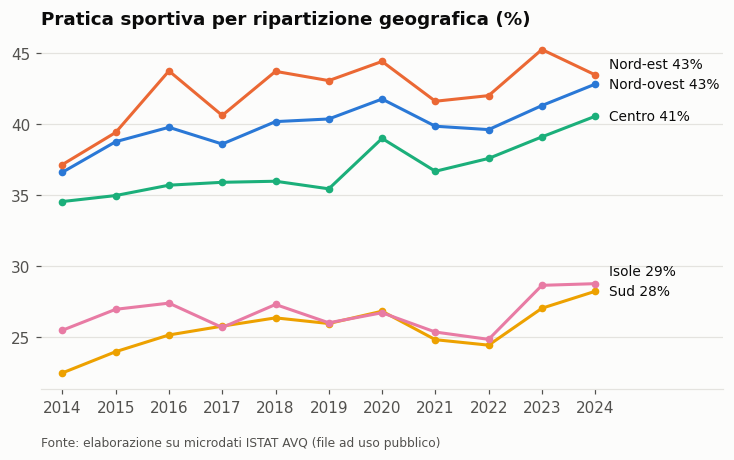

ripartizione,Nord-ovest,Nord-est,Centro,Sud,Isole
anno,,,,,
2014,36.6,37.2,34.6,22.5,25.5
2015,38.8,39.4,35.0,24.0,27.0
2016,39.8,43.8,35.7,25.2,27.4
2017,38.6,40.6,35.9,25.8,25.7
2018,40.2,43.7,36.0,26.4,27.3
2019,40.4,43.1,35.5,26.0,26.0
2020,41.8,44.4,39.0,26.8,26.7
2021,39.9,41.6,36.7,24.8,25.4
2022,39.6,42.0,37.6,24.5,24.9


In [10]:
rip = quota(dati, "pratica_sport", ["anno", "ripartizione"])
fig, ax = plt.subplots(figsize=(8, 4.2))
finali = []
for (r, g), c in zip(rip.groupby("ripartizione", observed=True), [BLU, ARANCIO, ACQUA, GIALLO, MAGENTA]):
    ax.plot(g.anno, g.quota, color=c, marker="o", markersize=4)
    finali.append((r, g.quota.iloc[-1]))
etichette_finali(ax, 2024, [v for _, v in finali], [f"{r} {v:.0f}%" for r, v in finali])
ax.set_title("Pratica sportiva per ripartizione geografica (%)")
ax.set_xticks(range(2014, 2025))
ax.set_xlim(2013.6, 2026.4)
fonte(ax)
salva(fig, "06_ripartizioni")
plt.show()
rip.pivot(index="anno", columns="ripartizione", values="quota").round(1)

## 5. Titolo di studio
Adulti 25-64 anni (in età più giovane il titolo di studio dipende dal percorso ancora in corso).

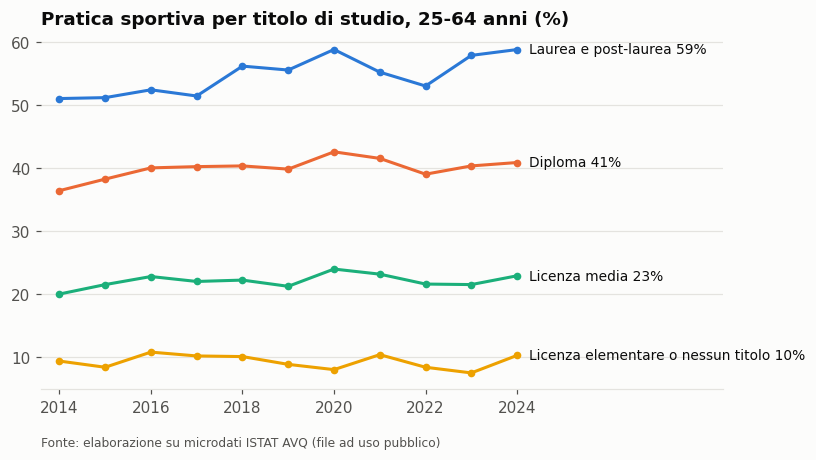

titolo_studio,Laurea e post-laurea,Diploma,Licenza media,Licenza elementare o nessun titolo
anno,,,,
2014,51.0,36.4,20.0,9.4
2015,51.2,38.3,21.5,8.4
2016,52.4,40.0,22.8,10.8
2017,51.4,40.2,22.0,10.2
2018,56.2,40.4,22.2,10.1
2019,55.6,39.8,21.3,8.9
2020,58.8,42.6,24.0,8.0
2021,55.2,41.5,23.2,10.4
2022,53.0,39.0,21.6,8.4


In [11]:
ADULTI = ["25-34", "35-44", "45-54", "55-59", "60-64"]
istr = quota(dati[dati.eta_classe.isin(ADULTI)], "pratica_sport", ["anno", "titolo_studio"])
istr.to_csv(RES / "pratica_titolo_studio.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 4.2))
for (t, g), c in zip(istr.groupby("titolo_studio", observed=True), [BLU, ARANCIO, ACQUA, GIALLO]):
    ax.plot(g.anno, g.quota, color=c, marker="o", markersize=4)
    ax.annotate(f"{t} {g.quota.iloc[-1]:.0f}%", (g.anno.iloc[-1], g.quota.iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=9)
ax.set_title("Pratica sportiva per titolo di studio, 25-64 anni (%)")
ax.set_xticks(range(2014, 2025, 2))
ax.set_xlim(2013.6, 2028.5)
fonte(ax)
salva(fig, "07_titolo_studio")
plt.show()
istr.pivot(index="anno", columns="titolo_studio", values="quota").round(1)

## 6. Sport e recupero scolastico (11-19 anni)
L'unica variabile dei microdati legata al carico scolastico è `lezioni_recupero` (lezioni private di recupero negli ultimi 12 mesi; manca nel 2017-2018). È un **proxy debole** della pressione scolastica: chi prende ripetizioni pratica meno sport?

È una **associazione**, non un effetto causale: entrambe le cose dipendono anche da reddito familiare, territorio e tipo di scuola.

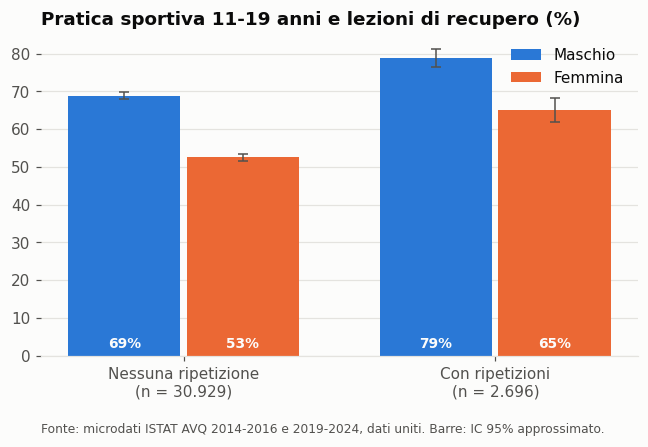

,ripetizioni,sesso,quota,ic_basso,ic_alto,n
0,Con ripetizioni,Maschio,78.8,76.4,81.2,1472.0
1,Con ripetizioni,Femmina,65.0,61.9,68.1,1224.0
2,Nessuna ripetizione,Maschio,68.9,68.0,69.7,15778.0
3,Nessuna ripetizione,Femmina,52.5,51.6,53.4,15151.0


In [12]:
TEEN = ["11-13", "14-15", "16-17", "18-19"]
teen = dati[dati.eta_classe.isin(TEEN) & dati.lezioni_recupero.notna()].copy()
teen["ripetizioni"] = np.where(teen.lezioni_recupero == "No", "Nessuna ripetizione", "Con ripetizioni")
rec = quota(teen, "pratica_sport", ["ripetizioni", "sesso"])
rec_tot = quota(teen, "pratica_sport", ["ripetizioni"])
rec.to_csv(RES / "pratica_recupero_scolastico.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 3.8))
gruppi = ["Nessuna ripetizione", "Con ripetizioni"]
larghezza = 0.36
for i, sesso in enumerate(["Maschio", "Femmina"]):
    g = rec[rec.sesso == sesso].set_index("ripetizioni").loc[gruppi]
    xpos = np.arange(2) + (i - 0.5) * (larghezza + 0.02)
    ax.bar(xpos, g.quota, width=larghezza, color=COLORI_SESSO[sesso], label=sesso)
    ax.errorbar(xpos, g.quota, yerr=[g.quota - g.ic_basso, g.ic_alto - g.quota], fmt="none",
                ecolor=TESTO_2, elinewidth=1, capsize=3)
    for xp, q in zip(xpos, g.quota):
        ax.annotate(f"{q:.0f}%", (xp, 2), ha="center", color=SUPERFICIE, fontsize=9, fontweight="bold")
ax.set_xticks(range(2), [f"{g}\n(n = {int(rec_tot.set_index('ripetizioni').loc[g, 'n']):,})".replace(",", ".") for g in gruppi])
ax.set_title("Pratica sportiva 11-19 anni e lezioni di recupero (%)")
ax.legend(loc="upper right")
fonte(ax, "Fonte: microdati ISTAT AVQ 2014-2016 e 2019-2024, dati uniti. Barre: IC 95% approssimato.", y=-0.24)
salva(fig, "08_recupero_scolastico")
plt.show()
rec.round(1)

## 7. Perché i giovani non fanno sport (tavole ISTAT 2024)
I microdati AVQ non contengono i motivi, quindi qui usiamo la **Tavola 9** del report ISTAT *La pratica sportiva in Italia – Anno 2024* (indagine "I cittadini e il tempo libero"), già convertita in `data/clean/motivi_non_pratica_2024.csv`.

Attenzione a due cose:
- la domanda è rivolta a **tutti quelli che non fanno sport**, sia chi ha smesso sia chi non ha mai iniziato;
- si possono dare **più risposte**, quindi le percentuali non sommano a 100.

Confrontiamo tre fasce: 11-14 anni (scuola media), 15-17 (scuola superiore) e 18-19 (fine delle superiori o inizio università). La tabella sotto il grafico riporta anche i 20-24enni.

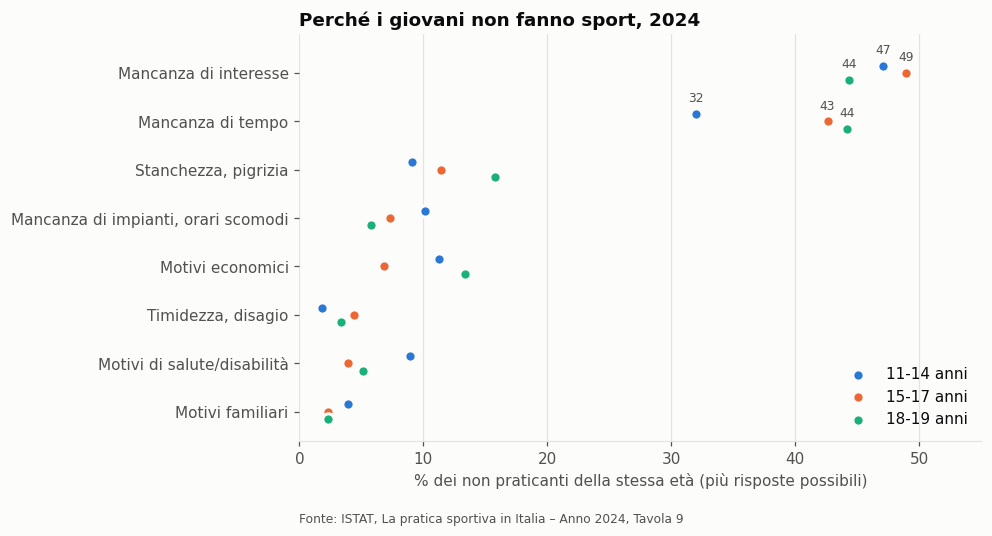

categoria,11-14,15-17,18-19,20-24
motivo,,,,
Mancanza di interesse,47.1,48.9,44.3,41.3
Mancanza di tempo,32.0,42.6,44.2,49.2
"Stanchezza, pigrizia",9.1,11.4,15.8,14.6
"Mancanza di impianti, orari scomodi",10.1,7.3,5.8,5.6
Motivi economici,11.3,6.8,13.4,9.7
"Timidezza, disagio",1.8,4.4,3.4,5.2
Motivi di salute/disabilità,8.9,3.9,5.1,4.1
Motivi familiari,3.9,2.3,2.3,2.4


In [13]:
motivi = pd.read_csv(ROOT / "data" / "clean" / "motivi_non_pratica_2024.csv")
FASCE = {"11-14": BLU, "15-17": ARANCIO, "18-19": ACQUA}
m = (motivi[(motivi.gruppo == "classi di età") & motivi.categoria.isin(["11-14", "15-17", "18-19", "20-24"])]
     .pivot(index="motivo", columns="categoria", values="valore")
     .drop(index="Età")  # motivo rilevante solo per bambini e anziani
     .sort_values("15-17")
     .rename(index=lambda s: re.sub(r",\s*", ", ", s)))
SPOSTAMENTO = {"11-14": 0.15, "15-17": 0, "18-19": -0.15}  # separa i punti con lo stesso valore

fig, ax = plt.subplots(figsize=(8, 4.8))
y = np.arange(len(m))
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
for fascia, colore in FASCE.items():
    ax.scatter(m[fascia], y + SPOSTAMENTO[fascia], color=colore, s=55, zorder=3, edgecolor=SUPERFICIE, linewidth=2,
               label=f"{fascia} anni")
for yi, motivo in enumerate(m.index[-2:], start=len(m) - 2):  # etichette solo sui due motivi principali
    for fascia in FASCE:
        ax.annotate(f"{m.loc[motivo, fascia]:.0f}", (m.loc[motivo, fascia], yi + SPOSTAMENTO[fascia]), xytext=(0, 8),
                    textcoords="offset points", ha="center", fontsize=8, color=TESTO_2)
ax.set_yticks(y, m.index)
ax.set_xlim(0, 55)
ax.set_ylim(-0.6, len(m) - 0.2)
ax.set_xlabel("% dei non praticanti della stessa età (più risposte possibili)")
ax.set_title("Perché i giovani non fanno sport, 2024")
ax.legend(loc="lower right")
fonte(ax, "Fonte: ISTAT, La pratica sportiva in Italia – Anno 2024, Tavola 9", y=-0.2)
salva(fig, "13_motivi_non_pratica_giovani")
plt.show()
m[["11-14", "15-17", "18-19", "20-24"]].sort_values("15-17", ascending=False)

**Lettura.** Tra gli 11-14enni il motivo principale è la **mancanza di interesse** (47%), mentre la mancanza di tempo è al 32%. Con l'età il **tempo** cresce fino a pareggiare l'interesse: 43% a 15-17 anni, 44% a 18-19 e 49% a 20-24. Il passaggio alle superiori coincide quindi con un aumento netto di chi dice di non avere tempo (+11 punti), compatibile con un maggiore carico di studio, anche se la tavola non dice *per cosa* manca il tempo. Impianti, orari e costi pesano molto meno (5-13%).

## Prime osservazioni (da rileggere e completare)
- **Andamento:** la pratica sportiva (3 anni e più) passa dal 31,8% nel 2014 al 37,7% nel 2024. Nel 2021 c'è un calo legato al COVID, che colpisce soprattutto gli 11-15enni (maschi dal 74% al 60%); nel 2022 si torna ai livelli di prima.
- **Genere:** il divario uomini-donne resta di circa 10 punti (2024: 43,0% contro 32,5%). Tra i giovani è massimo a 16-19 anni, dove le ragazze sono intorno al 50% contro il 65-70% dei ragazzi.
- **Età:** la pratica è massima tra 6 e 13 anni (maschi fino al 77% a 11-13 anni, femmine 66% a 6-10 anni). Per le ragazze il calo inizia già a 11-13 anni ed è netto a 14-15, per i ragazzi è più graduale.
- **Territorio:** la distanza tra il Trentino-Alto Adige (55%) e Calabria/Campania (22-24%) è enorme e cambia poco in dieci anni. Quasi tutte le regioni migliorano; la Calabria peggiora.
- **Titolo di studio (25-64 anni):** 59% tra i laureati contro 10% con al massimo la licenza elementare.
- **Motivi (tavole 2024):** tra gli 11-14enni che non fanno sport prevale la mancanza di interesse (47%); dalle superiori in poi cresce la mancanza di tempo (43% a 15-17 anni, 49% a 20-24), che arriva a pareggiare l'interesse. È l'indizio più diretto, nei dati ISTAT, a favore dell'ipotesi che studio e impegni tolgano tempo allo sport.
- **Recupero scolastico:** chi prende ripetizioni fa *più* sport (maschi 79% contro 69%, femmine 65% contro 53%). Il notebook 02 mostra che reddito e istruzione della famiglia spiegano solo una parte di questa differenza. Questo proxy quindi **non** supporta l'idea che il carico scolastico tolga tempo allo sport.

I grafici sono salvati in `figures/`, le tabelle in `results/`.